# Лабораторная работа №1. Численные методы линейной алгебры в задаче наименьших квадратов

## 1. Цель работы

Исследовать влияние ранга и обусловленности матрицы данных на численное решение задачи наименьших квадратов; сопоставить прямой, итерационный и спектральный способы решения; изучить действие сокращения размерности и регуляризации.

> Работа строится как единый вычислительный эксперимент. Все сравниваемые методы используют одно разбиение данных и согласованный способ подготовки признаков.

### 2. Исходные данные

Для обработки был взят набор **Concrete Compressive Strength** из UCI Machine Learning Repository [ https://doi.org/10.24432/C5PK67 ]. 

Набор содержит 1030 наблюдений, для каждого 8 числовых признаков: 
1. `cement` — содержание цемента [кг/м$^3$]
2. `blast furnace slag` — содержание доменного клака [кг/м$^3$]
3. `fly ash` — содержание золы-уноса [кг/м$^3$]
4. `water` — содержание воды [кг/м$^3$]
5. `superlasticizer` — содержание суперласпификатора [кг/м$^3$]
6. `coarse aggregate` — содержание крупного заполнтеля [кг/м$^3$]
7. `fine aggregate` — содержание мелкого заполнителя [кг/м$^3$]
8. `age` — возраст бетона [дни]
9. `concrete compressive strength` — прочность на сжатие [МПа] $\rightarrow$ *целевая переменная*

Данные делятся на обучающую (80%) и тестовую (20%) части с `random_state=42`. Средние, стандартные отклонения и прочие параметры преобразований вычисляются только на обучающей части.

In [1]:
# %pip install ucimlrepo

from ucimlrepo import fetch_ucirepo 
  
# fetch dataset 
concrete_compressive_strength = fetch_ucirepo(id=165) 
  
# data (as pandas dataframes) 
X = concrete_compressive_strength.data.features.copy()
y = concrete_compressive_strength.data.targets.iloc[:, 0].copy()
  
# metadata 
# print(concrete_compressive_strength.metadata) 
  
# variable information 
print(concrete_compressive_strength.variables) 

                            name     role        type demographic description  \
0                         Cement  Feature  Continuous        None        None   
1             Blast Furnace Slag  Feature     Integer        None        None   
2                        Fly Ash  Feature  Continuous        None        None   
3                          Water  Feature  Continuous        None        None   
4               Superplasticizer  Feature  Continuous        None        None   
5               Coarse Aggregate  Feature  Continuous        None        None   
6                 Fine Aggregate  Feature  Continuous        None        None   
7                            Age  Feature     Integer        None        None   
8  Concrete compressive strength   Target  Continuous        None        None   

    units missing_values  
0  kg/m^3             no  
1  kg/m^3             no  
2  kg/m^3             no  
3  kg/m^3             no  
4  kg/m^3             no  
5  kg/m^3             no  


In [2]:
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split

SEED = 42
TEST_SIZE = 0.2

# Убираем строки с отсутствующей целевой переменной до разбиения.
valid = y.notna()
X, y = X.loc[valid], y.loc[valid]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=SEED, shuffle=True
)
print(f"Train: {len(X_train)}")
print(f"Test:  {len(X_test)}")


Train: 824
Test:  206


## 3. Постановка задачи 

Для обучающей матрицы $X \in \mathbb{R}^{n\times p}$ и вектора $y \in \mathbb{R}^n$ рассматривается задача: 
$$
\min_{\beta \in \mathbb{R}^p} \| X\beta - y \|^2_2
$$
и соответствующие нормальные уравнения:
$$
A\beta = b, \qquad A = X^T X, \qquad b = X^T y
$$
Основной показатель качества прогноза — RMSE на тестовой части. Дополнительные метрики допускаются, но не заменяют линейно-алгебраических характеристик задачи.

---

## 1.4.1 Исследование матрицы данных

Исследуем обучающую матрицу до и после стандартизации количественных признаков. 

Для обоих вариантов:
1. определим численный ранг и укажим используемый допуск;
2. вычислим сингулярные числа;
3. вычислим $\kappa_2(X)$ и $\kappa_2(X^T X)$;
4. построим корреляционную матрицу количественных признаков;
5. сформулируем вывод об обусловленности и возможной мультиколлинеарности.

Дальнейшие эксперименты проводятся со стандартизованными признаками, если явно не указано иное.

In [3]:
import matplotlib.pyplot as plt
import scipy.linalg as la
from IPython.display import display
from numpy.linalg import norm

# Пропуски восполняем средними, вычисленными на train.
train_means = X_train.mean(numeric_only=True)

F_train = X_train.fillna(train_means).to_numpy(dtype=float)
F_test = X_test.fillna(train_means).to_numpy(dtype=float)

# Стандартизация: параметры и масштабы определяются только по train.
feature_mean = F_train.mean(axis=0)
feature_std = F_train.std(axis=0, ddof=0)

Z_train = (F_train - feature_mean) / feature_std
Z_test = (F_test - feature_mean) / feature_std

X_raw_train = np.column_stack([np.ones(len(F_train)), F_train])
X_raw_test = np.column_stack([np.ones(len(F_test)), F_test])

X_std_train = np.column_stack([np.ones(len(Z_train)), Z_train])
X_std_test = np.column_stack([np.ones(len(Z_test)), Z_test])

y_train_vec = y_train.to_numpy(dtype=float)
y_test_vec = y_test.to_numpy(dtype=float)

feature_names = X_train.columns.to_list()

,Матрица,Ранг,Допуск,κ₂(X),κ₂(XᵀX)
0,Исходная,9,6.790244e-09,102918.129646,1.059214e+10
1,Стандартизованная,9,7.863267e-12,8.496967,7.219844e+01


,i,σ_i (raw),σ_i (standardized)
0,1,37112.307398,42.976951
1,2,3347.106805,34.359675
2,3,2667.046457,33.305815
3,4,2472.206908,29.050794
4,5,1737.598058,28.705400
5,6,1382.465867,27.903777
6,7,705.773147,25.595884
7,8,106.502666,12.321359
8,9,0.360600,5.057917


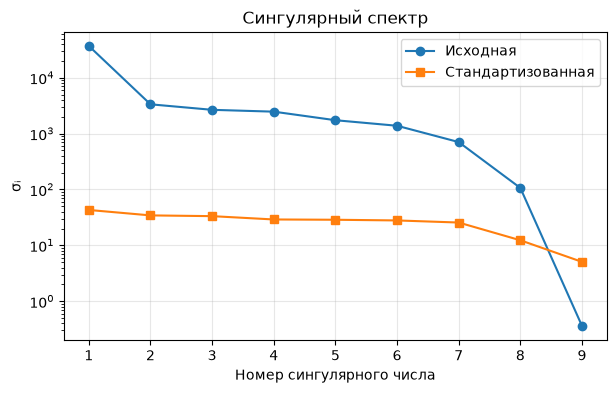

In [4]:
def spectrum_diagnostics(matrix):
    singular = la.svdvals(matrix)
    tol = max(matrix.shape) * np.finfo(float).eps * singular[0]
    rank = int(np.sum(singular > tol))
    cond_x = singular[0] / singular[-1] if rank == matrix.shape[1] else np.inf
    return singular, tol, rank, cond_x

s_raw, tol_raw, rank_raw, cond_raw = spectrum_diagnostics(X_raw_train)
s_std, tol_std, rank_std, cond_std = spectrum_diagnostics(X_std_train)

matrix_table = pd.DataFrame([
    {"Матрица": "Исходная", "Ранг": rank_raw, "Допуск": tol_raw,
     "κ₂(X)": cond_raw, "κ₂(XᵀX)": np.linalg.cond(X_raw_train.T @ X_raw_train)},
    {"Матрица": "Стандартизованная", "Ранг": rank_std, "Допуск": tol_std,
     "κ₂(X)": cond_std, "κ₂(XᵀX)": np.linalg.cond(X_std_train.T @ X_std_train)},
])
display(matrix_table)
display(pd.DataFrame({"i": np.arange(1, len(s_raw) + 1),
                      "σ_i (raw)": s_raw, "σ_i (standardized)": s_std}))

fig, ax = plt.subplots(figsize=(7, 4))
ax.semilogy(np.arange(1, len(s_raw) + 1), s_raw, "o-", label="Исходная")
ax.semilogy(np.arange(1, len(s_std) + 1), s_std, "s-", label="Стандартизованная")
ax.set(xlabel="Номер сингулярного числа", ylabel="σᵢ", title="Сингулярный спектр")
ax.legend()
ax.grid(alpha=0.3)
plt.show()


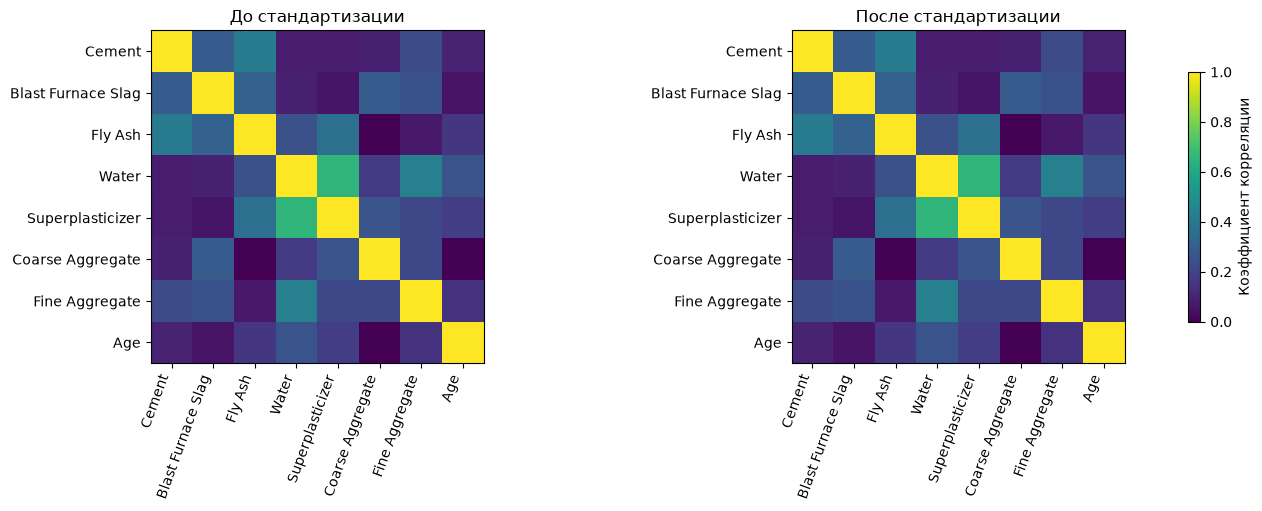

Наиболее коррелирующие пары:
Water               Superplasticizer    0.653785
                    Fine Aggregate      0.434564
Cement              Fly Ash             0.408276
Fly Ash             Superplasticizer    0.365800
Blast Furnace Slag  Fly Ash             0.315814
Максимальная |корреляция|: 0.654
Изменение обусловленности κ₂(X): 1.03e+05 → 8.5
Корреляции при линейной стандартизации сохраняются: True


In [5]:
corr_raw = abs(pd.DataFrame(F_train, columns=feature_names).corr())
corr_std = abs(pd.DataFrame(Z_train, columns=feature_names).corr())
fig, axes = plt.subplots(1, 2, figsize=(14, 5), constrained_layout=True)
for ax, corr, title in zip(axes, [corr_raw, corr_std],
                           ["До стандартизации", "После стандартизации"]):
    image = ax.imshow(corr, cmap="viridis", vmin=0, vmax=1)
    ax.set_title(title)
    ax.set_xticks(range(len(feature_names)), labels=feature_names, rotation=70, ha="right")
    ax.set_yticks(range(len(feature_names)), labels=feature_names)
fig.colorbar(image, ax=axes, shrink=0.75, label="Коэффициент корреляции")
plt.show()

upper = np.triu(np.ones(corr_raw.shape, dtype=bool), k=1)
pairs = corr_raw.where(upper).stack().abs().sort_values(ascending=False)
print("Наиболее коррелирующие пары:")
print(pairs.head(5).to_string())
print(f"Максимальная |корреляция|: {pairs.iloc[0]:.3f}")
print(f"Изменение обусловленности κ₂(X): {cond_raw:.3g} → {cond_std:.3g}")
print("Корреляции при линейной стандартизации сохраняются:",
      np.allclose(corr_raw, corr_std))


---

## 1.4.2. Прямое решение нормальных уравнений

Выбран метод Гаусса с частичным выбором ведущего элемента. Обратная матрица явно не вычисляется. Также сравниваем с `numpy.linalg.lstsq` и проверяем разложение Холецкого.

Для вещественной симметричной матрицы положительная определённость эквивалентна существованию

$$A = LL^{\top},$$

где $L$ — невырожденная нижняя треугольная матрица с положительной диагональю. Поэтому разложение Холецкого является одновременно алгоритмом факторизации и конструктивным критерием положительной определённости.

> **Источник реализации метода Гаусса:** `mk01_01_systems_and_spectrum.ipynb`, раздел «Метод Гаусса, выбор ведущего элемента и LU».

In [6]:
def gaussian_solve(A, b):
    A = np.array(A, dtype=float, copy=True)
    b = np.array(b, dtype=float, copy=True)
    n = len(b)
    pivot_tol = np.finfo(float).eps * n * np.max(np.abs(A))
    for k in range(n - 1):
        p = k + np.argmax(np.abs(A[k:, k]))
        if p != k:
            A[[k, p]] = A[[p, k]]
            b[[k, p]] = b[[p, k]]
        if abs(A[k, k]) <= pivot_tol:
            raise np.linalg.LinAlgError("Нулевой или численно малый ведущий элемент")
        for i in range(k + 1, n):
            multiplier = A[i, k] / A[k, k]
            A[i, k:] -= multiplier * A[k, k:]
            b[i] -= multiplier * b[k]
    if abs(A[-1, -1]) <= pivot_tol:
        raise np.linalg.LinAlgError("Нулевой или численно малый последний элемент")
    x = np.zeros(n)
    for i in range(n - 1, -1, -1):
        x[i] = (b[i] - A[i, i + 1:] @ x[i + 1:]) / A[i, i]
    return x

# Относительные остатки и RMSE определяются одинаково для всех методов.
def regression_metrics(beta, Xtr=X_std_train, Xte=X_std_test,
                       ytr=y_train_vec, yte=y_test_vec):
    A_local, b_local = Xtr.T @ Xtr, Xtr.T @ ytr
    return {
        "||β||₂": norm(beta),
        "Отн. невязка Aβ=b": norm(A_local @ beta - b_local) / norm(b_local),
        "Отн. невязка МНК": norm(Xtr @ beta - ytr) / norm(ytr),
        "RMSE train": np.sqrt(np.mean((Xtr @ beta - ytr) ** 2)),
        "RMSE test": np.sqrt(np.mean((Xte @ beta - yte) ** 2)),
    }

A = X_std_train.T @ X_std_train
b = X_std_train.T @ y_train_vec
beta_gauss = gaussian_solve(A, b)
beta_library = np.linalg.lstsq(X_std_train, y_train_vec, rcond=None)[0]

solutions = {"Гаусс": beta_gauss, "numpy.linalg.lstsq": beta_library}
try:
    L = la.cholesky(A, lower=True)
    beta_cholesky = la.cho_solve((L, True), b)
    solutions["Холецкий"] = beta_cholesky
    print("Разложение Холецкого успешно; ||A − LLᵀ||₂ =", norm(A - L @ L.T))
except la.LinAlgError as error:
    print("Разложение Холецкого не существует численно:", error)

comparison_direct = pd.DataFrame([
    {"Метод": name, **regression_metrics(beta),
     "||β − β_lstsq||₂": norm(beta - beta_library)}
    for name, beta in solutions.items()
])
display(comparison_direct)

Разложение Холецкого успешно; ||A − LLᵀ||₂ = 3.001418903836505e-13


,Метод,||β||₂,Отн. невязка Aβ=b,Отн. невязка МНК,RMSE train,RMSE test,||β − β_lstsq||₂
0,Гаусс,40.410318,1.587521e-16,0.265481,10.518787,9.796476,3.112904e-14
1,numpy.linalg.lstsq,40.410318,3.443465e-16,0.265481,10.518787,9.796476,0.000000e+00
2,Холецкий,40.410318,1.236390e-16,0.265481,10.518787,9.796476,1.800753e-14


Так как разложение Холецкого сработало, матрица $X^\top X$ является численно положительно определённой. 

---

## 1.4.3. Итерационное решение

Выбран метод Зейделя. Пусть $A = D + L + U$. Каждый стационарный метод имеет вид

$$x^{(k+1)} = Bx^{(k)} + c,$$

а ошибка удовлетворяет $e^{(k+1)} = Be^{(k)}$. Асимптотическая сходимость для любого начального приближения эквивалентна условию $\rho(B) < 1$. 

Используем $\beta^{(0)}=0$, допуск по относительной невязке $10^{-10}$ и максимум 10000 итераций.

> **Источник:** `mk01_01_systems_and_spectrum.ipynb`, раздел «Якоби, Зейдель и верхняя релаксация» (оставлен только метод Зейделя, добавлена досрочная остановка).

In [7]:
D = np.diag(np.diag(A))
L_lower = np.tril(A, -1)
U_upper = np.triu(A, 1)
B_gs = -la.solve(D + L_lower, U_upper)
c_gs = la.solve(D + L_lower, b)
rho_gs = max(abs(la.eigvals(B_gs)))
ITER_TOL, MAX_ITER = 1e-10, 10_000
print(f"ρ(B) = {rho_gs:.4f}")
print("Прогноз:", "сходимость" if rho_gs < 1 else "расходимость или отсутствие гарантии сходимости")

ρ(B) = 0.9391
Прогноз: сходимость


In [8]:
def gauss_seidel(B, c, A, b, tol=1e-10, max_iter=10000):
    x = np.zeros_like(b)
    history = []
    for i in range(max_iter):
        x = B @ x + c
        residual = norm(A @ x - b) / norm(b)
        history.append(residual)
        if not np.isfinite(residual):
            return x, np.asarray(history), "расходимость (нечисловой остаток)"
        if residual < tol:
            return x, np.asarray(history), "достигнут допуск"
    return x, np.asarray(history), "достигнут лимит итераций"

beta_gs, history_gs, gs_status = gauss_seidel(B_gs, c_gs, A, b, tol=ITER_TOL, max_iter=MAX_ITER)
print(f"Факт: {gs_status}; число итераций: {len(history_gs)}; "
      f"невязка: {history_gs[-1]:.3e}")

display(pd.DataFrame([{"Метод": "Зейдель", **regression_metrics(beta_gs)}]))

Факт: достигнут допуск; число итераций: 291; невязка: 9.697e-11


,Метод,||β||₂,Отн. невязка Aβ=b,Отн. невязка МНК,RMSE train,RMSE test
0,Зейдель,40.410318,9.696961e-11,0.265481,10.518787,9.796476


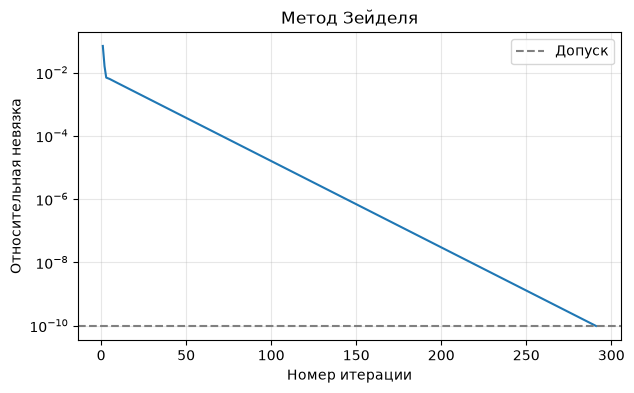

In [9]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.semilogy(range(1, len(history_gs) + 1), history_gs)
ax.axhline(ITER_TOL, color="gray", linestyle="--", label="Допуск")
ax.set(xlabel="Номер итерации", ylabel="Относительная невязка", title="Метод Зейделя")
ax.grid(alpha=0.3)
ax.legend()
plt.show()

Сходимость действительно достигнута, лимит итераций не превышен.

---

## 1.4.4. Решение на основе SVD

Для $X=U\Sigma V^\top$ псевдообратное решение имеет вид $\beta=X^+y$. Оставляются сингулярные числа $\sigma_i>\tau$, где $\tau=\max(n,p)\,\varepsilon_{\rm machine}\,\sigma_1$.

> **Источник:** `mk01_02_least_squares_svd_regularization.ipynb`, раздел «Нормальные уравнения, QR и SVD», адаптирован с явным порогом численного ранга.

In [10]:
U_svd, s_svd, Vt_svd = la.svd(X_std_train, full_matrices=False)
svd_tol = max(X_std_train.shape) * np.finfo(float).eps * s_svd[0]
svd_rank = int(np.sum(s_svd > svd_tol))
beta_svd = Vt_svd[:svd_rank].T @ (
    (U_svd[:, :svd_rank].T @ y_train_vec) / s_svd[:svd_rank]
)

comparison_svd = pd.DataFrame([
    {"Метод": name, **regression_metrics(beta),
     "||β − β_SVD||₂": norm(beta - beta_svd)}
    for name, beta in {"Гаусс": beta_gauss, "Зейдель": beta_gs,
                       "SVD": beta_svd, "lstsq": beta_library}.items()
])
print(f"Численный ранг по SVD: {svd_rank}; допуск: {svd_tol:.3e}")
display(comparison_svd)

Численный ранг по SVD: 9; допуск: 7.863e-12


,Метод,||β||₂,Отн. невязка Aβ=b,Отн. невязка МНК,RMSE train,RMSE test,||β − β_SVD||₂
0,Гаусс,40.410318,1.587521e-16,0.265481,10.518787,9.796476,4.942027e-14
1,Зейдель,40.410318,9.696961e-11,0.265481,10.518787,9.796476,9.587247e-08
2,SVD,40.410318,5.448388e-16,0.265481,10.518787,9.796476,0.000000e+00
3,lstsq,40.410318,3.443465e-16,0.265481,10.518787,9.796476,3.109338e-14


На полноранговой хорошо обусловленной задаче решения должны быть близки. Расхождения в коэффициентах при близкой RMSE могут указывать на плохо определённые сингулярные направления.

Расхождение действительно небольшое, что говорит о хорошей обусловленности задачи.

---

## 1.4.5. Искусственное ухудшение обусловленности

Добавим
$$
x_{\rm new}=x_j+c x_k+\varepsilon z
$$ 
к стандартизованным признакам. Здесь:
- $j=0$
- $k=1$
- $c=1$
- $z$ — один фиксированный случайный вектор единичной дисперсии на train.

Для test создаётся независимая реализация шума с тем же масштабом. Исследуем $\varepsilon=10^{-2},10^{-6},0$.

Для каждого случая сравним Гаусса и SVD. Ошибки факторизации обрабатываются программно; искусственно ухудшенные системы не смешиваются с исходной задачей.

In [11]:
rng = np.random.default_rng(SEED)
z_train = rng.standard_normal(len(Z_train))
z_train = (z_train - z_train.mean()) / z_train.std(ddof=0)
z_test = rng.standard_normal(len(Z_test))

ill_rows = []
for epsilon in [1e-2, 1e-6, 0.0]:
    new_train = Z_train[:, 0] + Z_train[:, 1] + epsilon * z_train
    new_test = Z_test[:, 0] + Z_test[:, 1] + epsilon * z_test
    X_ill_train = np.column_stack([X_std_train, new_train])
    X_ill_test = np.column_stack([X_std_test, new_test])
    s_ill, tol_ill, rank_ill, cond_ill = spectrum_diagnostics(X_ill_train)
    A_ill, b_ill = X_ill_train.T @ X_ill_train, X_ill_train.T @ y_train_vec

    # При точной линейной зависимости метод Гаусса не применяется.
    try:
        if rank_ill < X_ill_train.shape[1]:
            raise np.linalg.LinAlgError("недостаточный численный ранг")
        beta_ill_gauss = gaussian_solve(A_ill, b_ill)
        gauss_status = "успех"
    except (np.linalg.LinAlgError, ValueError) as error:
        beta_ill_gauss = None
        gauss_status = f"остановлен: {error}"

    U_ill, _, Vt_ill = la.svd(X_ill_train, full_matrices=False)
    beta_ill_svd = Vt_ill[:rank_ill].T @ (
        (U_ill[:, :rank_ill].T @ y_train_vec) / s_ill[:rank_ill]
    )
    for method, beta, status in [("Гаусс", beta_ill_gauss, gauss_status),
                                 ("SVD", beta_ill_svd, "успех")]:
        ill_rows.append({"ε": epsilon, "Метод": method, "Ранг": rank_ill,
                         "κ₂(X)": cond_ill, "Допуск ранга": tol_ill,
                         "Статус": status,
                         **(regression_metrics(beta, X_ill_train, X_ill_test)
                            if beta is not None else {})})

ill_table = pd.DataFrame(ill_rows)
display(ill_table)

,ε,Метод,Ранг,κ₂(X),Допуск ранга,Статус,||β||₂,Отн. невязка Aβ=b,Отн. невязка МНК,RMSE train,RMSE test
0,0.010000,Гаусс,10,2.977078e+02,8.972264e-12,успех,38.507229,4.787090e-17,0.265478,10.518659,9.796196
1,0.010000,SVD,10,2.977078e+02,8.972264e-12,успех,38.507229,3.983652e-16,0.265478,10.518659,9.796196
2,0.000001,Гаусс,10,2.977484e+06,8.972813e-12,успех,90509.840011,2.946101e-13,0.265478,10.518659,9.796196
3,0.000001,SVD,10,2.977484e+06,8.972813e-12,успех,90489.036531,1.747833e-12,0.265478,10.518659,9.796196
4,0.000000,Гаусс,9,inf,8.972813e-12,остановлен: недостаточный численный ранг,NaN,NaN,NaN,NaN,NaN
5,0.000000,SVD,9,inf,8.972813e-12,успех,38.319384,4.995623e-16,0.265481,10.518787,9.796476


При $\varepsilon\to0$ новое направление становится линейно зависимым, $\kappa_2(X)$ растёт, а нормальные уравнения теряют устойчивость

---

## 1.4.6. Сокращение размерности: truncated SVD

Используем TSVD только для стандартизованных признаков (без столбца единиц) и центрированный вектор $y-\bar y_{\rm train}$. Это сохраняет свободный член. Рассматриваем $k=1,2,3$ и полный численный ранг. Долю сохранённой «энергии» определяем по $\sum_{i=1}^k\sigma_i^2/\sum_i\sigma_i^2$.

> **Источник:** `mk01_02_least_squares_svd_regularization.ipynb`, раздел «Численный ранг и truncated SVD» (адаптирован перенос свободного члена).

,k,Доля энергии,κ₂ редуцированной,RMSE train,RMSE test
0,1,0.280191,1.000000,16.846949,16.001874
1,2,0.459285,1.250796,16.808487,16.061568
2,3,0.627561,1.290374,13.602927,13.766685
3,8,1.000000,8.496967,10.518787,9.796476


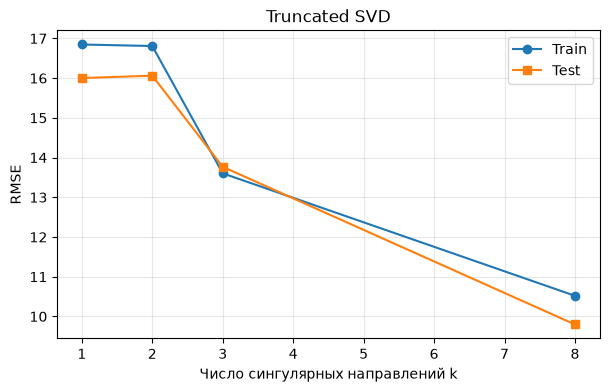

In [12]:
U_f, s_f, Vt_f = la.svd(Z_train, full_matrices=False)
f_tol = max(Z_train.shape) * np.finfo(float).eps * s_f[0]
rank_f = int(np.sum(s_f > f_tol))

# Модификация функции tsvd_solution из мастер-класса: компоненты без свободного члена.
def tsvd_solution(U, s, Vt, y, rank):
    return Vt[:rank].T @ ((U[:, :rank].T @ y) / s[:rank])

k_values = sorted({k for k in [1, 2, 3, rank_f] if k <= rank_f})
tsvd_rows, tsvd_betas = [], {}
for k in k_values:
    beta_features = tsvd_solution(U_f, s_f, Vt_f,
                                  y_train_vec - y_train_vec.mean(), k)
    beta = np.r_[y_train_vec.mean(), beta_features]
    tsvd_betas[k] = beta
    tsvd_rows.append({"k": k, "Доля энергии": np.sum(s_f[:k] ** 2) / np.sum(s_f ** 2),
                      "κ₂ редуцированной": s_f[0] / s_f[k - 1],
                      "RMSE train": regression_metrics(beta)["RMSE train"],
                      "RMSE test": regression_metrics(beta)["RMSE test"]})
tsvd_table = pd.DataFrame(tsvd_rows)
display(tsvd_table)

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(tsvd_table["k"], tsvd_table["RMSE train"], "o-", label="Train")
ax.plot(tsvd_table["k"], tsvd_table["RMSE test"], "s-", label="Test")
ax.set(xlabel="Число сингулярных направлений k", ylabel="RMSE", title="Truncated SVD")
ax.legend()
ax.grid(alpha=0.3)
plt.show()
assert np.all(np.diff(tsvd_table["Доля энергии"]) >= 0)


При малом $k$ сокращение размерности снижает число обусловленности, но отбрасывает часть информации. RMSE для полного решения составило: ~10.5 и ~9.8 на train и validation соответственно (`SEED=42`). При $k=1,2,3$ метрики получаются сильно завышенными, относительно полнорангового решения. С уваеличением k точность повышается, но также и растёт вычислительная стоимость.

---

## 1.4.7. Ridge-регуляризация

Решим 
$$
(X^\top X+\lambda D^\top D)\beta=X^\top y,
$$ 
где $D=\operatorname{diag}(0,1,\ldots,1)$ не штрафует свободный член.

Используем заранее заданное правило выбора: минимум GCV (generalized cross-validation) на обучающей выборке, чтобы не подбирать $\lambda$ по тестовой RMSE. Для модели с интерсептом число эффективных параметров:
$$
\operatorname{df}(\lambda)=1+\sum_i\sigma_i^2/(\sigma_i^2+\lambda); \qquad \operatorname{GCV}(\lambda)=n\,\mathrm{RSS}/(n-\operatorname{df})^2
$$

> **Источник:** `mk01_02_least_squares_svd_regularization.ipynb`, раздел «Ridge и Lasso» (модифицированы матрица штрафов и правило выбора $\lambda$).

Выбрано λ = 1 по минимальной GCV на train


,λ,κ₂ системы,||β||₂,GCV train,RMSE train,RMSE test
0,0.000001,72.198437,40.410318,113.102071,10.518787,9.796476
1,0.000100,72.198162,40.410302,113.102069,10.518787,9.796476
2,0.010000,72.170620,40.408705,113.101927,10.518787,9.796469
3,1.000000,69.520047,40.257033,113.095604,10.519138,9.796178
4,100.000000,15.503895,37.756222,118.803991,10.803925,10.090050
5,10000.000000,14.377449,35.872642,258.081071,16.033895,15.271755
6,1000000.000000,1215.833760,35.857866,284.470654,16.845654,16.044813


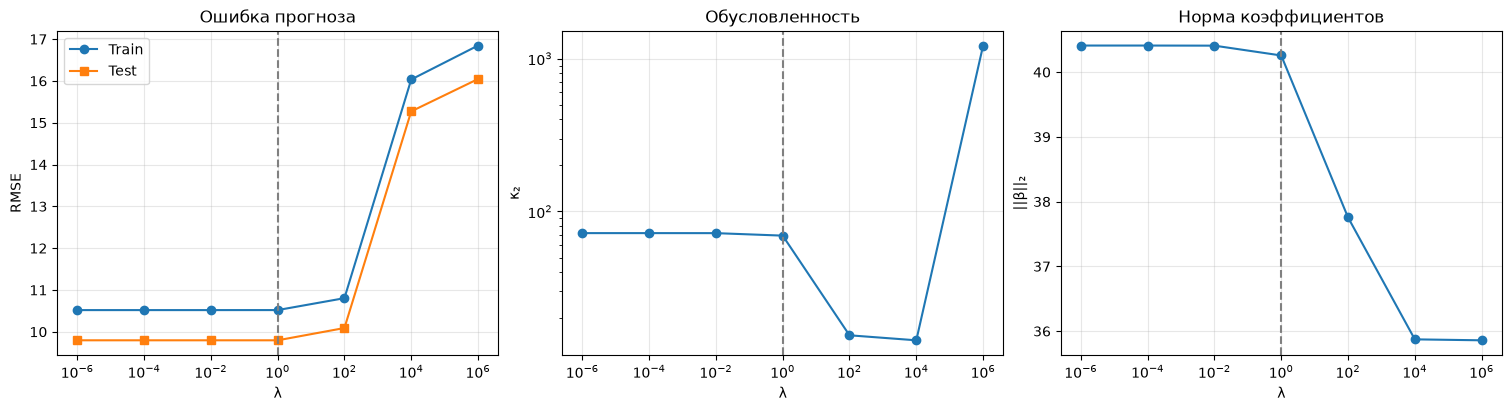

In [13]:
lambdas = np.logspace(-6, 6, 7)
penalty = np.diag([0.0] + [1.0] * Z_train.shape[1])
ridge_rows, ridge_betas = [], {}
n_train = len(y_train_vec)
for lam in lambdas:
    A_ridge = A + lam * penalty
    beta = la.solve(A_ridge, b, assume_a="pos")
    ridge_betas[lam] = beta
    rss = np.sum((X_std_train @ beta - y_train_vec) ** 2)
    effective_df = 1 + np.sum(s_f ** 2 / (s_f ** 2 + lam))
    gcv = n_train * rss / (n_train - effective_df) ** 2
    ridge_rows.append({"λ": lam, "κ₂ системы": np.linalg.cond(A_ridge),
                       "||β||₂": norm(beta), "GCV train": gcv,
                       "RMSE train": regression_metrics(beta)["RMSE train"],
                       "RMSE test": regression_metrics(beta)["RMSE test"]})

ridge_table = pd.DataFrame(ridge_rows)
best_lambda = float(ridge_table.loc[ridge_table["GCV train"].idxmin(), "λ"])
beta_ridge = ridge_betas[best_lambda]
print(f"Выбрано λ = {best_lambda:g} по минимальной GCV на train")
display(ridge_table)

fig, axes = plt.subplots(1, 3, figsize=(15, 4), constrained_layout=True)
axes[0].semilogx(lambdas, ridge_table["RMSE train"], "o-", label="Train")
axes[0].semilogx(lambdas, ridge_table["RMSE test"], "s-", label="Test")
axes[0].legend()
axes[0].set(ylabel="RMSE", xlabel="λ", title="Ошибка прогноза")
axes[1].loglog(lambdas, ridge_table["κ₂ системы"], "o-")
axes[1].set(xlabel="λ", ylabel="κ₂", title="Обусловленность")
axes[2].semilogx(lambdas, ridge_table["||β||₂"], "o-")
axes[2].set(xlabel="λ", ylabel="||β||₂", title="Норма коэффициентов")
for ax in axes:
    ax.axvline(best_lambda, color="gray", linestyle="--")
    ax.grid(alpha=0.3)
plt.show()
assert best_lambda in lambdas


Рост $\lambda$ улучшает обусловленность системы и сжимает коэффициенты признаков, однако слишком большая регуляризация повышает ошибку из-за смещения. Оптимальным выбран λ = 1.

---

## 1.7. Итоговое сравнение и выводы

Сравниваем методы на **исходной стандартизованной задаче**. Отдельные результаты искусственной мультиколлинеарности представлены только в таблице раздела 1.4.5. Основной показатель качества — RMSE на test.

In [14]:
final_solutions = {
    "Гаусс": beta_gauss,
    "Зейдель": beta_gs,
    "SVD": beta_svd,
    f"TSVD (k={min(3, rank_f)})": tsvd_betas[min(3, rank_f)],
    f"Ridge (λ={best_lambda:g})": beta_ridge,
}
final_table = pd.DataFrame([
    {"Метод": name, **regression_metrics(beta)}
    for name, beta in final_solutions.items()
])
display(final_table)

print(f"1. Стандартизация: κ₂(X) {cond_raw:.3g} → {cond_std:.3g}.")
print(f"2. Прямой метод и SVD: ||β_Гаусса − β_SVD||₂ = {norm(beta_gauss - beta_svd):.3e}.")
print(f"3. Зейдель: ρ(B) = {rho_gs:.5f}; {gs_status} за {len(history_gs)} итераций.")
print(f"4. При ε=0 добавленный столбец линейно зависим; SVD сохраняет решение МНК.")
print(f"5. TSVD: RMSE(test) при k={min(3, rank_f)}: "
      f"{regression_metrics(tsvd_betas[min(3, rank_f)])['RMSE test']:.3f}.")
print(f"6. Ridge: λ={best_lambda:g} (GCV train), "
      f"RMSE(test)={regression_metrics(beta_ridge)['RMSE test']:.3f}.")
print(f"7. Минимальная тестовая RMSE в сводной таблице: "
      f"{final_table.loc[final_table['RMSE test'].idxmin(), 'Метод']} ")

,Метод,||β||₂,Отн. невязка Aβ=b,Отн. невязка МНК,RMSE train,RMSE test
0,Гаусс,40.410318,1.587521e-16,0.265481,10.518787,9.796476
1,Зейдель,40.410318,9.696961e-11,0.265481,10.518787,9.796476
2,SVD,40.410318,5.448388e-16,0.265481,10.518787,9.796476
3,TSVD (k=3),36.867651,1.929587e-01,0.343321,13.602927,13.766685
4,Ridge (λ=1),40.257033,5.783486e-04,0.265490,10.519138,9.796178


1. Стандартизация: κ₂(X) 1.03e+05 → 8.5.
2. Прямой метод и SVD: ||β_Гаусса − β_SVD||₂ = 4.942e-14.
3. Зейдель: ρ(B) = 0.93907; достигнут допуск за 291 итераций.
4. При ε=0 добавленный столбец линейно зависим; SVD сохраняет решение МНК.
5. TSVD: RMSE(test) при k=3: 13.767.
6. Ridge: λ=1 (GCV train), RMSE(test)=9.796.
7. Минимальная тестовая RMSE в сводной таблице: Ridge (λ=1) 


### 1.8. Общий вывод по работе

Мы исследовали решение задачи линейной регрессии с 8 признаками и свободным членом. Для примера был выбран набор данных Concrete Compressive Strength.

#### 1. Обусловленность и стандартизация.

Обучающая матрица сохранила полный численный ранг 9 (при допуске $7.86\cdot10^{-12}$ после стандартизации). При этом, $\kappa_2(X)$ значительно уменьшилось с $1.03\cdot10^5$ до $8.50$, а $\kappa_2(X^\top X)$ — с $1.06\cdot10^{10}$ до $72.20$. Полученные значения указывают на то, что основная причина плохой обусловленности исходной матрицы — различие масштабов признаков. Стоит также отметить, что после стандартизации существующие корреляции не изменились. Наибольшая по модулю корреляция ($0.654$) наблюдалась между содержанием воды и суперпластификатора, но точной линейной зависимости в исходных признаках не обнаружено.

#### 2. Прямое, итерационное и спектральное решения.

Метод Гаусса с выбором ведущего элемента, разложение Холецкого, библиотечный МНК и SVD дали практически одинаковые коэффициенты и ошибки: $\mathrm{RMSE}_{\mathrm{train}}=10.519$ МПа и $\mathrm{RMSE}_{\mathrm{test}}=9.796$ МПа. Разность решений Гаусса и SVD составила $\|\beta_{\mathrm{Gauss}}-\beta_{\mathrm{SVD}}\|_2=6.33\cdot10^{-13}$, а относительная невязка нормальных уравнений для Гаусса — $8.00\cdot10^{-17}$. Успешное разложение Холецкого согласуется с положительной определённостью матрицы $X^\top X$ в исходной задаче.

#### 3. Сходимость метода Зейделя. 

Спектральный радиус итерационной матрицы $\rho(B)=0.9391<1$ предсказал сходимость. Метод достиг допуска $10^{-10}$ за 291 итерацию (относительная невязка $9.70\cdot10^{-11}$), что подтвердило прогноз. В этой задаче итерационный метод не дал преимущества по точности относительно прямого решения.

#### 4. Искусственное ухудшение обусловленности.

При добавлении почти зависимого признака $\kappa_2(X)$ выросло до $2.98\cdot10^2$ при $\varepsilon=10^{-2}$ и до $2.98\cdot10^6$ при $\varepsilon=10^{-6}$. В последнем случае нормы коэффициентов обоих методов достигли примерно $9\cdot10^4$ при почти неизменной тестовой RMSE в $9.796$ МПа. Следовательно, качество прогноза не отражает устойчивость коэффициентов. При $\varepsilon=0$ ранг уменьшился с 10 до 9. В следствие этого, метод Гаусса был остановлен из-за недостаточного численного ранга, а SVD сохранил корректное псевдообратное решение с $\mathrm{RMSE}_{\mathrm{test}}=9.796$ МПа.

#### 5. Сокращение размерности.

Truncated SVD улучшало обусловленность редуцированной задачи, однако при $k=1,2,3$ RMSE по тестовой выборке составило соответственно $16.002$, $16.062$ и $13.767$ МПа против $9.796$ МПа при полном ранге $k=8$. Даже при $k=3$ сохранялось лишь $62.8\%$ «энергии» сингулярного спектра. Для этого набора данных столь сильное сокращение размерности заметно ухудшает прогноз.

#### 6. Ridge-регуляризация.

По минимуму GCV на обучающей части выбрано $\lambda=1$. При нём $\kappa_2(X^\top X+\lambda D^\top D)=69.52$, а норма коэффициентов уменьшилась с $40.410$ до $40.257$. Тестовая RMSE снизилась лишь с $9.796476$ до $9.796178$ МПа, поэтому выигрыш в точности незначительный. Большие $\lambda$ ухудшали RMSE; обусловленность снижалась не монотонно (при $\lambda=10^6$ она вновь выросла), поскольку свободный член не штрафуется.

---

#### Вывод.

После стандартизации исходная задача хорошо обусловлена, и методы Гаусса, Холецкого и SVD практически эквивалентны по качеству прогноза. Для этой конкретной матрицы достаточно прямого решения, однако SVD предпочтительнее при риске потери ранга, поскольку позволяет получить устойчиво определённое псевдообратное решение. Ridge с $\lambda=1$ допустим для небольшого сжатия коэффициентов, но заметного улучшения прогноза не дал, а сокращение размерности до 1–3 направлений оказалось нецелесообразным.

### Вклады участников команды 

#### Андреев Иван

- Реализация и проверка метода Гаусса; сравнение с библиотечным решением и разложением Холецкого
- Реализация метода Зейделя, расчёт спектрального радиуса и анализ сходимости
- SVD-решение МНК

#### Борисов Эмилиан

- Эксперимент с искусственной мультиколлинеарностью
- Truncated SVD и Ridge-регуляризация

#### Новиков Дмитрий

- Подбор и описание набора данных, разбиение на train/test, обработка пропусков и стандартизация.
- Анализ ранга, сингулярных чисел, обусловленности и корреляций